# Bài tập thực hành 4: Hồi quy MLP dự đoán giá nhà King County

Notebook demo 14 bước của đề bài. Logic dùng lại nằm trong `src/house_price/`; notebook chỉ gọi module đó để demo và thí nghiệm.

> Trạng thái: khung notebook Phase 1. Chưa chạy huấn luyện, chưa có kết quả.

## 1. Import thư viện

Chạy cell code bên dưới sau khi cài đặt xong (`pip install -r requirements.txt`).

In [1]:
import sys
sys.path.insert(0, 'src')  # chỉ dùng khi chạy notebook từ thư mục gốc repo

from house_price.preprocessing import prepare_data
from house_price.models import MLPRegressorModel, LinearRegressorModel
from house_price.evaluation import regression_metrics
print('TODO: Sinh viên 3 điền code chạy pipeline ở các bước dưới')


TODO: Sinh viên 3 điền code chạy pipeline ở các bước dưới


## 2. Nạp dữ liệu nhà ở

File: `data/kc_house_data_NaN/data_raw/kc_house_data_NaN.csv` (21.613 dòng). Xem `docs/king-county-dataset.md`.

### Sinh vien 1 - 1. Gioi thieu bo du lieu

Bo du lieu la King County House Sales, giao dich nha o quan King County, bang Washington, Hoa Ky (gom Seattle), tu thang 5/2014 den thang 5/2015. Bien muc tieu la `price` (gia ban, USD). File goc la `data/kc_house_data_NaN/data_raw/kc_house_data_NaN.csv`.

Tap du lieu co 21.613 dong va 22 cot: 1 cot chi muc goc `Unnamed: 0`, 1 ma can nha `id`, 1 ngay giao dich `date`, 1 bien muc tieu `price` va 18 cot dac trung goc (phong ngu, phong tam, dien tich, tang, waterfront, view, condition, grade, nam xay, nam cai tao, zipcode, toa do, dien tich lan can). Ba cot `Unnamed: 0`, `id`, `date` bi loai khoi tap huan luyen, nhung `id` van duoc giu lai de chia tap theo nhom o muc 8 va `date` duoc dung de tinh tuoi nha o muc 7.

Day la bo du lieu thay cho Boston Housing trong de vi du: file da co san trong repo, du lon va co gia tri khuyet that de xu ly. Gia ban trai rong tu 75.000 USD den 7.700.000 USD, trung vi 450.000 USD, trung binh 540.088 USD, nen phan bo lech phai manh (xem muc 3 va muc 6).


In [2]:
from pathlib import Path

from house_price.preprocessing import load_raw_dataset

# nbconvert chay kernel tu thu muc notebooks/, con JupyterLab co the chay tu goc repo.
# Tim goc repo bang file CSV de ca hai cach chay deu doc dung duong dan.
REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "data" / "kc_house_data_NaN" / "data_raw" / "kc_house_data_NaN.csv").is_file():
    REPO_ROOT = REPO_ROOT.parent
DATA_PATH = REPO_ROOT / "data" / "kc_house_data_NaN" / "data_raw" / "kc_house_data_NaN.csv"
EDA_DIR = REPO_ROOT / "outputs" / "eda"
raw = load_raw_dataset(DATA_PATH)

print(f"So dong: {raw.shape[0]:,}")
print(f"So cot: {raw.shape[1]}")
print(f"Ten cot: {list(raw.columns)}")
print(f"Khoang ngay giao dich: {raw['date'].min()} den {raw['date'].max()}")
print(f"So id duy nhat: {raw['id'].nunique():,}")
print(raw["price"].describe().round(2))


So dong: 21,613
So cot: 22
Ten cot: ['Unnamed: 0', 'id', 'date', 'price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'yr_built', 'yr_renovated', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15']
Khoang ngay giao dich: 20140502T000000 den 20150527T000000
So id duy nhat: 21,436
count      21613.00
mean      540088.14
std       367127.20
min        75000.00
25%       321950.00
50%       450000.00
75%       645000.00
max      7700000.00
Name: price, dtype: float64


### Sinh vien 1 - 2. Phan tich chat luong du lieu

Kiem tra tong quan truoc khi xu ly: gia tri khuyet, dong trung, pham vi tung cot va cac bat thuong ghi chep.

- Gia tri khuyet: chi 2 cot co khuyet, `bedrooms` 13 gia tri (0,06%) va `bathrooms` 10 gia tri (0,05%), tong 23 gia tri. Cac cot khac co 0 gia tri khuyet.
- Dong trung: khong co dong trung hoan toan (0 dong). Trung lap chi xay ra o ma `id` (xem muc 5).
- Bat thuong ghi chep: 12 dong co `yr_built` lon hon nam ban (tuoi nha am), se duoc kep ve 0 o muc 7 thay vi xoa dong. Cot `yr_renovated` bang 0 o 20.699 dong (95,8%), khac 0 o 914 dong (4,2%); theo quy uoc cua du lieu, 0 nghia la chua tung cai tao.
- Pham vi: `bedrooms` 1-33, `bathrooms` 0,5-8, `sqft_living` 290-13.540 (trung vi 1.910), `sqft_lot` 520-1.651.359, `yr_built` 1900-2015, `waterfront` bang 1 o 163 dong (0,75%), `grade` tap trung o 7 (8.981 dong) va 8 (6.068 dong), `zipcode` co 70 ma.

Ket luan: du lieu sach o muc co ban, khong co cot nao thieu nang den muc phai loai bo. Cac van de con lai (khuyet, trung id, ngoai lai) duoc xu ly rieng o muc 4, 5, 6.


In [3]:
print("Gia tri khuyet theo cot (chi cot co khuyet):")
missing = raw.isna().sum()
print(missing[missing > 0])
print(f"Tong gia tri khuyet: {int(raw.isna().sum().sum())}")
print(f"Dong trung hoan toan: {int(raw.duplicated().sum())}")
print(f"Dong co yr_built lon hon nam ban: {int((raw['date'].astype(str).str.slice(0, 4).astype(int) - raw['yr_built'] < 0).sum())}")
print(f"Dong yr_renovated = 0 (chua cai tao): {int((raw['yr_renovated'] == 0).sum()):,} / {len(raw):,}")
print(f"Dong waterfront = 1: {int(raw['waterfront'].sum())}")
print(f"So ma zipcode duy nhat: {raw['zipcode'].nunique()}")
print(raw[["bedrooms", "bathrooms", "sqft_living", "sqft_lot", "yr_built", "grade"]].describe().round(2))


Gia tri khuyet theo cot (chi cot co khuyet):
bedrooms     13
bathrooms    10
dtype: int64
Tong gia tri khuyet: 23
Dong trung hoan toan: 0
Dong co yr_built lon hon nam ban: 12
Dong yr_renovated = 0 (chua cai tao): 20,699 / 21,613
Dong waterfront = 1: 163
So ma zipcode duy nhat: 70
       bedrooms  bathrooms  sqft_living    sqft_lot  yr_built     grade
count  21600.00   21603.00     21613.00    21613.00  21613.00  21613.00
mean       3.37       2.12      2079.90    15106.97   1971.01      7.66
std        0.93       0.77       918.44    41420.51     29.37      1.18
min        1.00       0.50       290.00      520.00   1900.00      1.00
25%        3.00       1.75      1427.00     5040.00   1951.00      7.00
50%        3.00       2.25      1910.00     7618.00   1975.00      7.00
75%        4.00       2.50      2550.00    10688.00   1997.00      8.00
max       33.00       8.00     13540.00  1651359.00   2015.00     13.00


### Sinh vien 1 - 3. Phan tich kham pha du lieu (EDA)

Bieu do duoc ve bang cac ham trong `house_price.eda`, moi bieu do vua hien thi o day vua duoc luu vao `outputs/eda/`.

- Phan bo gia: lech phai manh, do lech (skew) 4,02, kurtosis 34,59. Trung vi 450.000 USD thap hon trung binh 540.088 USD. P90 887.000 USD, P95 1.156.480 USD, P99 1.964.400 USD. Phan lon nha tap trung duoi 1 trieu USD, duoi phai dai la nha cao cap that, khong phai loi do.
- Tuong quan Pearson voi `price`: `sqft_living` 0,702, `grade` 0,667, `sqft_above` 0,606, `sqft_living15` 0,585, `bathrooms` 0,526, `view` 0,397, `sqft_basement` 0,324, `bedrooms` 0,309, `lat` 0,307, `waterfront` 0,266, `floors` 0,257, `yr_renovated` 0,126, `sqft_lot` 0,090, `zipcode` -0,053, `condition` 0,036. Dien tich song va chat luong xay dung la hai yeu to manh nhat.
- Gia trung binh theo `grade` tang don dieu: grade 6 la 301.920 USD, 7 la 402.590 USD, 8 la 542.853 USD, 9 la 773.513 USD, 10 la 1.071.771 USD, 11 la 1.496.842 USD, 12 la 2.191.222 USD, 13 la 3.709.615 USD. Nha giap nuoc co gia trung binh 1.661.876 USD, gap hon 3 lan nha khong giap nuoc (531.564 USD), nhung chi co 163 can giap nuoc nen dac trung nay hiem.

Nhan xet cho mo hinh: gia lech phai manh nen chi so RMSE se bi keo boi nha dat tien; can doc kem MAE va R2 khi danh gia o buoc 9. Khong bien doi log cho `price` o giai doan nay vi muc tieu giu nguyen don vi USD de so sanh truc tiep.


price            1.000
sqft_living      0.702
grade            0.667
sqft_above       0.606
sqft_living15    0.585
bathrooms        0.526
view             0.397
sqft_basement    0.324
bedrooms         0.309
lat              0.307
waterfront       0.266
floors           0.257
yr_renovated     0.126
sqft_lot         0.090
sqft_lot15       0.082
yr_built         0.054
condition        0.036
Unnamed: 0       0.027
long             0.022
id              -0.017
zipcode         -0.053
Name: price, dtype: float64
grade
1      142000.0
3      205667.0
4      214381.0
5      248524.0
6      301920.0
7      402590.0
8      542853.0
9      773513.0
10    1071771.0
11    1496842.0
12    2191222.0
13    3709615.0
Name: price, dtype: float64
waterfront
0     531564.0
1    1661876.0
Name: price, dtype: float64


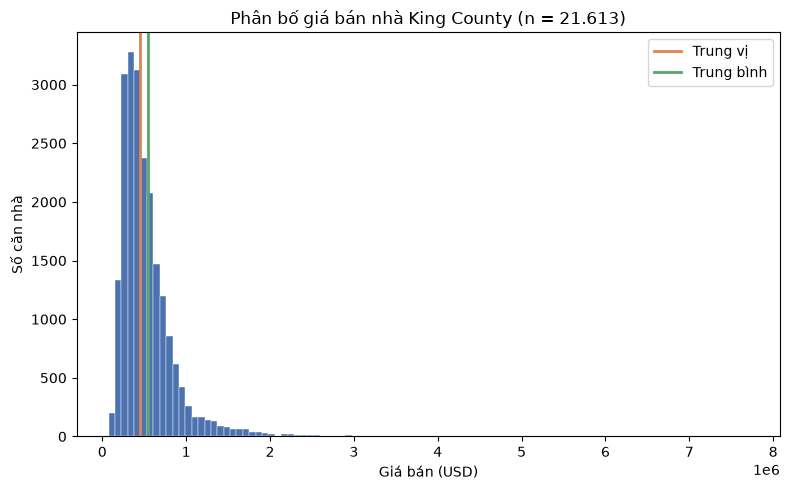

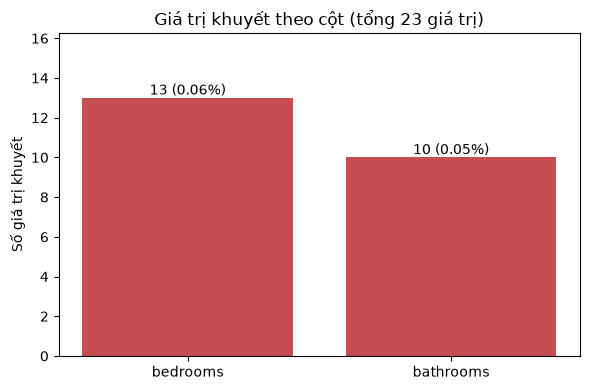

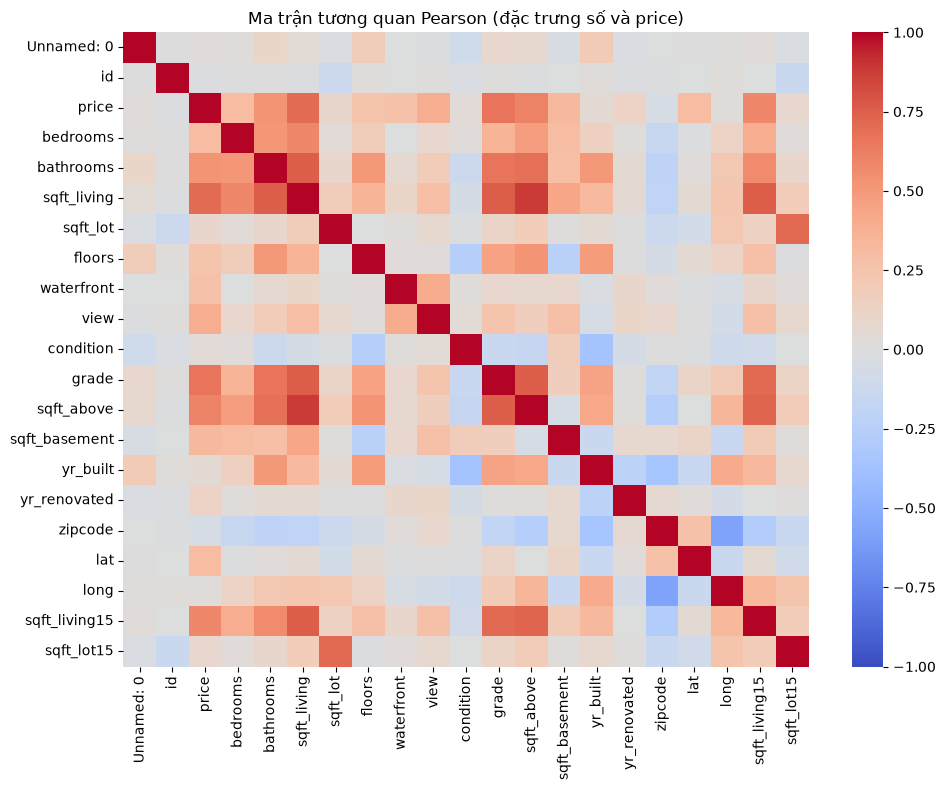

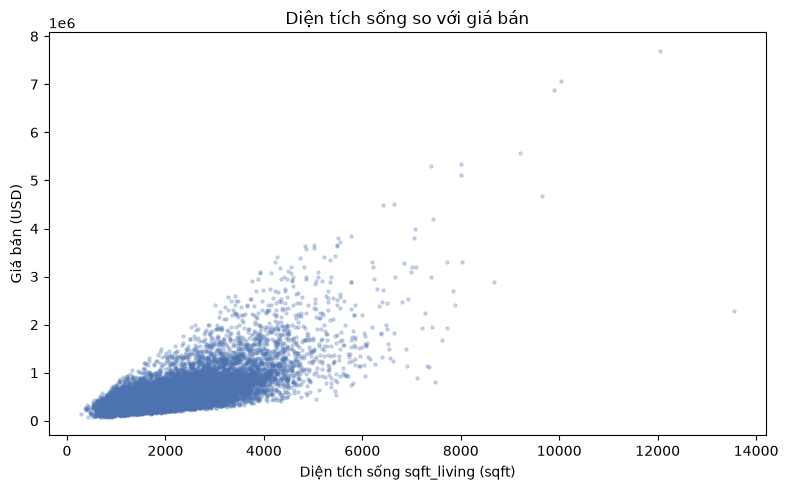

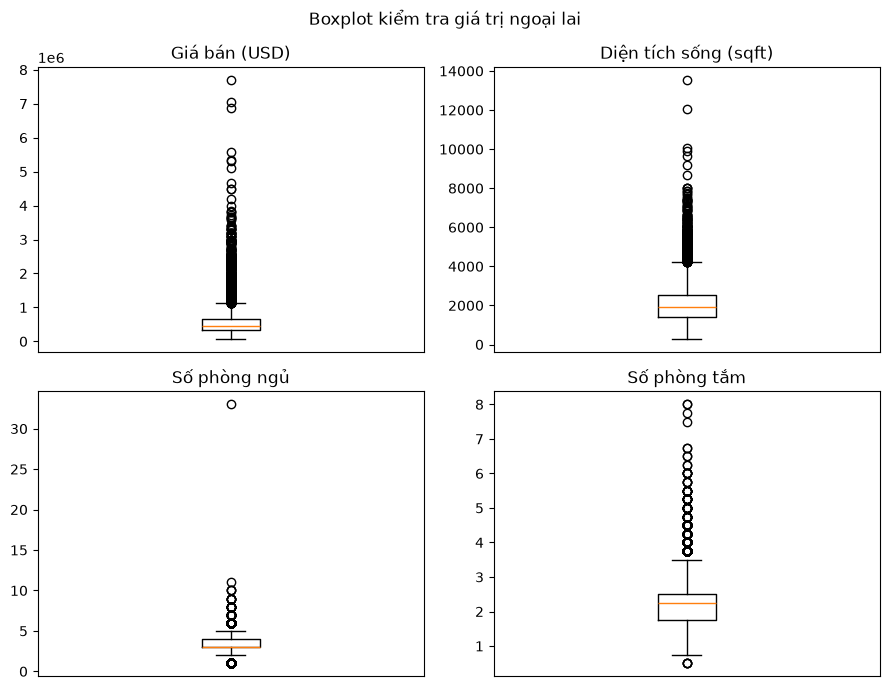

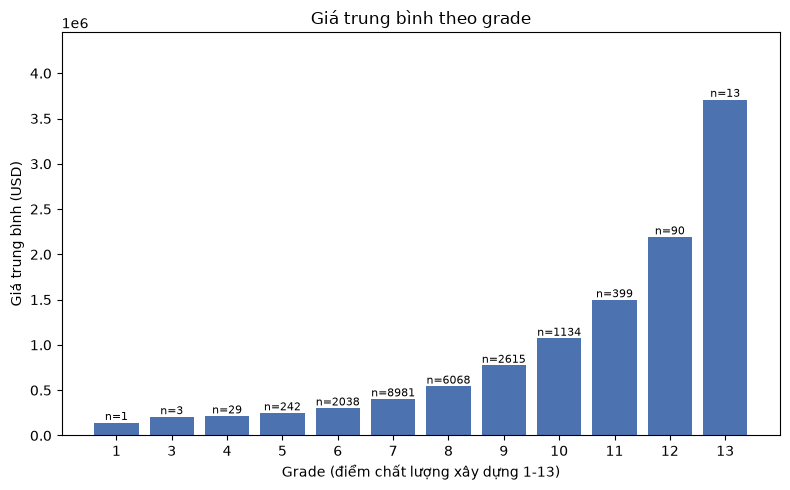

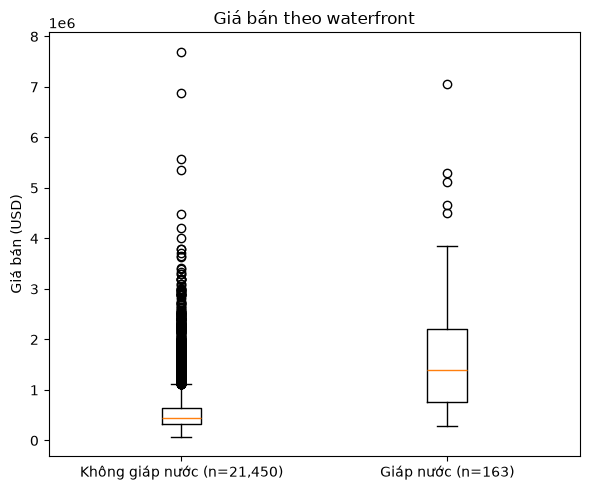

In [4]:
import matplotlib.pyplot as plt

from house_price import eda

corr_with_price = raw.corr(numeric_only=True)["price"].sort_values(ascending=False)
print(corr_with_price.round(3))
print(raw.groupby("grade")["price"].mean().round(0))
print(raw.groupby("waterfront")["price"].mean().round(0))

eda.plot_price_distribution(raw, save_path=EDA_DIR / "price_distribution.png")
plt.show()
eda.plot_missing_values(raw, save_path=EDA_DIR / "missing_values.png")
plt.show()
eda.plot_correlation_heatmap(raw, save_path=EDA_DIR / "correlation_heatmap.png")
plt.show()
eda.plot_sqft_living_vs_price(raw, save_path=EDA_DIR / "sqft_living_vs_price.png")
plt.show()
eda.plot_outlier_boxplots(raw, save_path=EDA_DIR / "outlier_boxplots.png")
plt.show()
eda.plot_mean_price_by_grade(raw, save_path=EDA_DIR / "mean_price_by_grade.png")
plt.show()
eda.plot_price_by_waterfront(raw, save_path=EDA_DIR / "price_by_waterfront.png")
plt.show()


### Sinh vien 1 - 4. Gia tri khuyet (Missing Values)

Chi `bedrooms` khuyet 13 gia tri (0,06%) va `bathrooms` khuyet 10 gia tri (0,05%); tong 23 gia tri tren 21.613 dong, cac cot khac khong khuyet. Ty le khuyet qua nho de anh huong dang ke, va khong co bang chung khuyet theo co che co he thong, nen khong xoa dong.

Cach xu ly: bu bang median cua tap train trong preprocessor (xem muc 9). Median duoc chon vi ben vung hon trung binh truoc gia tri ngoai lai nhu can 33 phong ngu. Imputer chi fit tren train, roi transform val/test, nen khong ro ri thong tin tu tap danh gia. Gia tri khuyet o `bedrooms` cung lam `sqft_per_bedroom` khuyet 13 gia tri o muc 7, va cung duoc bu bang median cua train theo cung co che.


bedrooms: 13 gia tri khuyet (0.06%)
bathrooms: 10 gia tri khuyet (0.05%)
Tong: 23 gia tri khuyet
So dong co it nhat 1 gia tri khuyet: 16


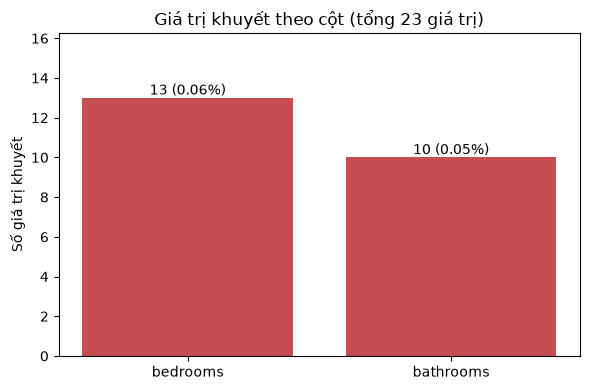

In [5]:
from house_price.eda import plot_missing_values

missing = raw.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
for column, count in missing.items():
    print(f"{column}: {count} gia tri khuyet ({100 * count / len(raw):.2f}%)")
print(f"Tong: {int(missing.sum())} gia tri khuyet")
print(f"So dong co it nhat 1 gia tri khuyet: {int(raw.isna().any(axis=1).sum())}")

plot_missing_values(raw, save_path=EDA_DIR / "missing_values.png")
plt.show()


### Sinh vien 1 - 5. Dieu tra dong trung lap (Duplicate Investigation)

Khong co dong trung hoan toan (0 dong). Trung lap chi o ma `id`: 21.436 id duy nhat tren 21.613 dong, 176 id lap lai (175 id xuat hien 2 lan, 1 id xuat hien 3 lan), tong 353 dong lien quan va 177 dong thua so voi 1 dong/id.

Kiem tra tung nhom id trung: khong nhom nao co cung ngay giao dich (0 nhom), 173/176 nhom co gia khac nhau giua cac lan ban, chi 3 nhom giong het nhau o moi cot mo hinh tru `id`/`date`, va khoang cach ngay lon nhat trong cung id la 315 ngay. Mau nay khop voi cung can nha duoc ban lap lai vao thoi diem khac nhau, gia thay doi theo thi truong, khong phai ban ghi trung do loi nhap lieu.

Quyet dinh: giu toan bo 21.613 dong, khong xoa dong trung id. Ly do: moi lan ban la mot quan sat gia that, xoa di se mat thong tin va lam meo phan bo gia. Rui ro con lai (cung can nha xuat hien o ca train va test) duoc xu ly bang chia tap theo nhom `id` o muc 8, thay vi xoa du lieu.


In [6]:
import pandas as pd

duplicated_id = raw[raw.duplicated("id", keep=False)].copy()
duplicated_id["sale_date"] = raw["date"].astype(str).str.slice(0, 8)
id_counts = raw["id"].value_counts()
print(f"Dong trung hoan toan: {int(raw.duplicated().sum())}")
print(f"So id duy nhat: {raw['id'].nunique():,}")
print(f"So id lap lai: {int((id_counts > 1).sum())} (xuat hien 2 lan: {int((id_counts == 2).sum())}, 3 lan: {int((id_counts == 3).sum())})")
print(f"Dong lien quan den id lap: {len(duplicated_id)}")
print(f"Dong thua so voi 1 dong/id: {int((id_counts - 1).clip(lower=0).sum())}")

grouped = duplicated_id.groupby("id")
same_date_groups = int((grouped["sale_date"].nunique() == 1).sum())
diff_price_groups = int((grouped["price"].nunique() > 1).sum())
model_columns = [c for c in raw.columns if c not in ("id", "date", "Unnamed: 0")]
identical_rows = duplicated_id.duplicated(subset=model_columns, keep=False)
identical_groups = int(duplicated_id[identical_rows]["id"].nunique())
sale_dates = duplicated_id.copy()
sale_dates["sale_date_dt"] = pd.to_datetime(sale_dates["sale_date"], format="%Y%m%d")
max_spread = int((sale_dates.groupby("id")["sale_date_dt"].max() - sale_dates.groupby("id")["sale_date_dt"].min()).dt.days.max())
print(f"Nhom id trung co cung ngay giao dich: {same_date_groups}")
print(f"Nhom id trung co gia khac nhau: {diff_price_groups} / {int((id_counts > 1).sum())}")
print(f"Nhom giong het nhau o moi cot mo hinh tru id/date: {identical_groups}")
print(f"Khoang cach ngay lon nhat trong cung id: {max_spread} ngay")


Dong trung hoan toan: 0
So id duy nhat: 21,436
So id lap lai: 176 (xuat hien 2 lan: 175, 3 lan: 1)
Dong lien quan den id lap: 353
Dong thua so voi 1 dong/id: 177
Nhom id trung co cung ngay giao dich: 0
Nhom id trung co gia khac nhau: 173 / 176
Nhom giong het nhau o moi cot mo hinh tru id/date: 3
Khoang cach ngay lon nhat trong cung id: 315 ngay


### Sinh vien 1 - 6. Phan tich gia tri ngoai lai (Outlier Analysis)

Gia ban lech phai rat manh: min 75.000 USD, Q1 321.950 USD, trung vi 450.000 USD, trung binh 540.088 USD, Q3 645.000 USD, max 7.700.000 USD, do lech 4,02, kurtosis 34,59. Nguong tren theo IQR la 1.129.575 USD, co 1.146 dong vuot nguong (5,3%). Tren 1 trieu USD co 1.465 dong (6,8%), tren 2 trieu USD co 198 dong.

Quyet dinh: KHONG xoa outlier theo IQR. Ly do: 5,3% du lieu vuot nguong IQR la qua nhieu de goi la loi, va nha tren 1 trieu USD la phan khuc cao cap that cua King County (gia tang dan deu theo grade va waterfront o muc 3). Xoa chung se lam mo hinh khong hoc duoc phan khuc dat tien va lam meo danh gia tren test.

Cac ngoai lai don le khac cung duoc giu lai va ghi chu: 1 dong co 33 phong ngu nhung chi 1.620 sqft dien tich song (nghi ngo nhap lieu, nhung chi 1 dong nen khong anh huong dang ke), `sqft_living` toi da 13.540 sqft, `sqft_lot` toi da 1.651.359 sqft. `StandardScaler` o muc 9 nhay cam voi ngoai lai, day la gioi han da biet va duoc ghi nhan, khong phai ly do de xoa du lieu that.


count      21613.00
mean      540088.14
std       367127.20
min        75000.00
25%       321950.00
50%       450000.00
75%       645000.00
max      7700000.00
Name: price, dtype: float64
Do lech (skew): 4.02
Kurtosis: 34.59
P90: 887,000 USD, P95: 1,156,480 USD, P99: 1,964,400 USD
Nguong tren IQR: 1,129,575 USD
Dong vuot nguong IQR: 1146 (5.3%)
Dong tren 1 trieu USD: 1465 (6.8%)
Dong tren 2 trieu USD: 198
bedrooms           33.00
bathrooms           1.75
sqft_living      1620.00
price          640000.00
Name: 15870, dtype: float64


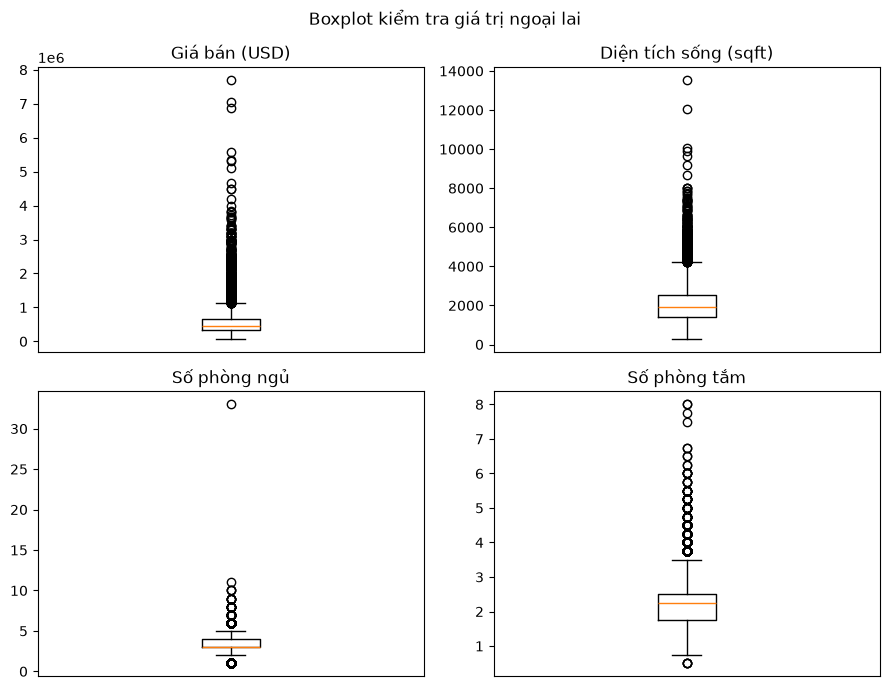

In [7]:
from house_price.eda import plot_outlier_boxplots

price = raw["price"]
q1, q3 = price.quantile(0.25), price.quantile(0.75)
iqr_upper = q3 + 1.5 * (q3 - q1)
print(price.describe().round(2))
print(f"Do lech (skew): {float(price.skew()):.2f}")
print(f"Kurtosis: {float(price.kurtosis()):.2f}")
print(f"P90: {price.quantile(0.90):,.0f} USD, P95: {price.quantile(0.95):,.0f} USD, P99: {price.quantile(0.99):,.0f} USD")
print(f"Nguong tren IQR: {iqr_upper:,.0f} USD")
print(f"Dong vuot nguong IQR: {int((price > iqr_upper).sum())} ({100 * (price > iqr_upper).mean():.1f}%)")
print(f"Dong tren 1 trieu USD: {int((price > 1_000_000).sum())} ({100 * (price > 1_000_000).mean():.1f}%)")
print(f"Dong tren 2 trieu USD: {int((price > 2_000_000).sum())}")
print(raw.loc[raw["bedrooms"].idxmax(), ["bedrooms", "bathrooms", "sqft_living", "price"]])

plot_outlier_boxplots(raw, save_path=EDA_DIR / "outlier_boxplots.png")
plt.show()


## 3. Tách đặc trưng X và mục tiêu y

`X`: 18 cột đặc trưng. `y`: cột `price`. Cột `id`, `date`, index gốc bị loại.

### Sinh vien 1 - 7. Ky thuat dac trung (Feature Engineering)

Ba dac trung moi duoc tao bang `engineer_features`, khong dung bien muc tieu `price` nen khong ro ri du lieu:

- `house_age = nam ban - yr_built`, kep toi thieu 0. Co 12 dong co `yr_built` lon hon nam ban (tuoi am do loi ghi) duoc kep ve 0 thay vi xoa. Ket qua: `house_age` tu 0 den 115, trung vi 40, trung binh 43,3; tuong quan voi `price` la -0,054 (nha cang cu gia cang thap nhe). Cot `yr_built` goc duoc thay bang `house_age` vi hai cot gan nhu trung thong tin trong cung mot nam ban.
- `was_renovated = 1` neu `yr_renovated > 0`, nguoc lai 0. Gia tri so cua `yr_renovated` tron co hieu voi nam (0 nghia la chua cai tao), nen khong dung truc tiep lam dac trung so. Co 4,23% dong bang 1; tuong quan voi `price` la 0,126, giong het tuong quan cua `yr_renovated` goc.
- `sqft_per_bedroom = sqft_living / bedrooms`: dien tich song trung binh moi phong ngu, phan anh do rong rai cua can nha. Pham vi 49,1-3.420, trung vi 576,7; 13 gia tri NaN do `bedrooms` khuyet, se duoc bu bang median cua train o muc 9. Tuong quan voi `price` la 0,580, manh thu hai chi sau `sqft_living`.

Luu y ve API doi so voi Phase 1: `FEATURE_COLUMNS` co 19 cot dau vao (18 so + `zipcode`), khong phai 18 cot nhu buoc 3 ghi theo ban cu. 18 cot so la 15 cot goc giu nguyen cong `house_age`, `was_renovated`, `sqft_per_bedroom`; `zipcode` la ma vung, khong phai so lien tuc, nen se duoc one-hot o muc 9 thay vi chuan hoa nhu so.


In [8]:
from house_price.preprocessing import FEATURE_COLUMNS, clean_dataset, engineer_features, split_features_target

engineered = engineer_features(raw)
print(engineered[["house_age", "was_renovated", "sqft_per_bedroom"]].describe().round(2))
print(f"So gia tri NaN cua sqft_per_bedroom: {int(engineered['sqft_per_bedroom'].isna().sum())}")
print(engineered[["house_age", "was_renovated", "sqft_per_bedroom", "price"]].corr(numeric_only=True)["price"].round(3))
print(f"FEATURE_COLUMNS ({len(FEATURE_COLUMNS)} cot): {FEATURE_COLUMNS}")

cleaned = clean_dataset(raw)
X, y = split_features_target(cleaned)
print(f"X: {X.shape}, y: {y.shape}")
print(f"Cot cua X: {list(X.columns)}")


       house_age  was_renovated  sqft_per_bedroom
count   21613.00       21613.00          21600.00
mean       43.32           0.04            618.15
std        29.37           0.20            215.88
min         0.00           0.00             49.09
25%        18.00           0.00            470.00
50%        40.00           0.00            576.67
75%        63.00           0.00            722.50
max       115.00           1.00           3420.00
So gia tri NaN cua sqft_per_bedroom: 13
house_age          -0.054
was_renovated       0.126
sqft_per_bedroom    0.580
price               1.000
Name: price, dtype: float64
FEATURE_COLUMNS (19 cot): ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'house_age', 'was_renovated', 'sqft_per_bedroom', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'zipcode']
X: (21613, 19), y: (21613,)
Cot cua X: ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'wate

## 4. Chia train/validation/test (70/15/15, seed 42)

Khác với DESIGN.md gốc (chỉ train/test 80/20): tập validation tách riêng để chọn mô hình, tập test chỉ dùng một lần cuối. Xem `docs/adr/003-chia-train-validation-test.md`.

### Sinh vien 1 - 8. Chia tap train/validation/test (Train/Validation/Test Split)

Chia theo ty le 70/15/15, `random_state=42`, bang `split_train_val_test`. Khac voi Phase 1 chi chia ngau nhien theo dong, ban hien tai chia theo nhom `id` (`GroupShuffleSplit` khi truyen `groups=...`): moi giao dich cua cung mot can nha nam trong cung mot partition.

Ly do doi cach chia: muc 5 cho thay 176 can nha duoc ban lap lai. Chia ngau nhien theo dong cu (seed 42) de lot 41 dong test va 38 dong validation co `id` trung voi train, nghia la mo hinh duoc danh gia tren can nha no da thay, lam R2 tren test lac quan gia. Chia theo nhom moi cho 0 dong trung `id` giua train voi val/test, nen danh gia do kha nang du doan can nha chua thay.

Kich thuoc sau chia theo nhom: train 15.129 dong, validation 3.243 dong, test 3.241 dong. Hoi quy khong co nhan lop nen khong stratify; chi xao tron ngau nhien voi seed co dinh de ket qua tai lap duoc. Tap test chi dung mot lan cuoi o buoc 9, khong dung de chon mo hinh.


In [9]:
from house_price.preprocessing import split_train_val_test

house_ids = raw["id"]

X_train_random, X_val_random, X_test_random, y_train_random, y_val_random, y_test_random = split_train_val_test(X, y)
train_ids_random = set(house_ids.loc[y_train_random.index])
leak_test_random = len(train_ids_random & set(house_ids.loc[y_test_random.index]))
leak_val_random = len(train_ids_random & set(house_ids.loc[y_val_random.index]))
print(f"Chia ngau nhien cu: train {X_train_random.shape}, val {X_val_random.shape}, test {X_test_random.shape}")
print(f"Chia ngau nhien cu: {leak_test_random} dong test trung id voi train, {leak_val_random} dong val trung id voi train")

X_train, X_val, X_test, y_train, y_val, y_test = split_train_val_test(X, y, groups=house_ids)
train_ids = set(house_ids.loc[y_train.index])
leak_test = len(train_ids & set(house_ids.loc[y_test.index]))
leak_val = len(train_ids & set(house_ids.loc[y_val.index]))
print(f"Chia theo nhom id: train {X_train.shape}, val {X_val.shape}, test {X_test.shape}")
print(f"Chia theo nhom id: {leak_test} dong test trung id voi train, {leak_val} dong val trung id voi train")


Chia ngau nhien cu: train (15129, 19), val (3242, 19), test (3242, 19)
Chia ngau nhien cu: 41 dong test trung id voi train, 38 dong val trung id voi train
Chia theo nhom id: train (15129, 19), val (3243, 19), test (3241, 19)
Chia theo nhom id: 0 dong test trung id voi train, 0 dong val trung id voi train


## 5. Chuẩn hóa đặc trưng

`StandardScaler` chỉ fit trên train, transform val/test. Bù khuyết median cũng chỉ fit trên train.

### Sinh vien 1 - 9. Tien xu ly (Preprocessing)

Preprocessor duoc tao bang `build_preprocessor` va chi fit tren tap train, roi transform val/test bang cung doi tuong da fit. Thu tu nay chong ro ri du lieu: median bu khuyet, trung binh va do lech chuan cua scaler, gia tri thuong gap nhat cua `zipcode` deu chi hoc tu train.

- Dac trung so (18 cot): bu khuyet bang median, roi `StandardScaler` (tru trung binh, chia do lech chuan cua train).
- `zipcode` (ma vung, khong phai so lien tuc): bu gia tri thuong gap nhat, roi one-hot voi `handle_unknown="ignore"` (ma chua thay o train cho toan 0). Co 70 ma zipcode o tap train, nen one-hot tao 70 cot.

Ket qua: `X_train` (15.129, 88), `X_val` (3.243, 88), `X_test` (3.241, 88), kieu `float64`, khong con NaN hay inf. 88 cot sau ma hoa gom 18 dac trung so da chuan hoa cong 70 cot one-hot zipcode. Code o day chi goi ham tu `house_price.preprocessing`, khong viet lai logic imputer, scaler hay one-hot trong notebook.


In [10]:
import numpy as np

from house_price.preprocessing import build_preprocessor, output_feature_names

preprocessor = build_preprocessor(X_train)
X_train_prep = preprocessor.transform(X_train)
X_val_prep = preprocessor.transform(X_val)
X_test_prep = preprocessor.transform(X_test)
feature_names = output_feature_names(preprocessor)

print(f"X_train: {X_train_prep.shape}, X_val: {X_val_prep.shape}, X_test: {X_test_prep.shape}")
print(f"Kieu du lieu: {X_train_prep.dtype}")
print(f"So cot sau ma hoa: {len(feature_names)} (18 so + {len(feature_names) - 18} one-hot zipcode)")
print(f"NaN o X_train: {bool(np.isnan(X_train_prep).any())}, inf o X_train: {bool(np.isinf(X_train_prep).any())}")
print(f"NaN o X_val: {bool(np.isnan(X_val_prep).any())}, NaN o X_test: {bool(np.isnan(X_test_prep).any())}")
print(f"10 cot dau: {feature_names[:10]}")


X_train: (15129, 88), X_val: (3243, 88), X_test: (3241, 88)
Kieu du lieu: float64
So cot sau ma hoa: 88 (18 so + 70 one-hot zipcode)
NaN o X_train: False, inf o X_train: False
NaN o X_val: False, NaN o X_test: False
10 cot dau: ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above']


### Sinh vien 1 - 10. Tong ket tap du lieu da chuan bi (Prepared Dataset Summary)

Ham `prepare_data` chay tron pipeline muc 1-9 trong mot lan goi: nap du lieu, ky thuat dac trung, tach X/y, chia 3 tap theo nhom `id`, fit preprocessor tren train, transform ca 3 tap. Ket qua khop hoan toan voi cac buoc rieng le o tren.

- Tap cuoi: `X_train` (15.129, 88), `X_val` (3.243, 88), `X_test` (3.241, 88), kieu `float64`, khong NaN/inf. 18 dac trung so + one-hot 70 zipcode.
- Muc tieu: `y_train` trung binh 537.298 USD, `y_val` trung binh 547.304 USD, `y_test` trung binh 545.893 USD. Chenh lech nho giua cac tap cho thay chia nhom khong lam lech phan bo gia.
- `prepare_data` tra them `input_columns` (19 cot dau vao truoc ma hoa) va `id_train`/`id_val`/`id_test` (ma `id` can nha theo tung partition, chi de kiem chung chia theo nhom, khong phai dac trung mo hinh). Kiem chung: 0 id trung giua train voi val/test.

Tap du lieu da san sang cho Sinh vien 2 (MLP, buoc 6-8) va Sinh vien 3 (danh gia, buoc 9-11). Cac buoc 6-14 ben duoi giu nguyen, khong doi.


In [11]:
from house_price.preprocessing import prepare_data

result = prepare_data(DATA_PATH)
print(f"X_train: {result['X_train'].shape}, X_val: {result['X_val'].shape}, X_test: {result['X_test'].shape}")
print(f"Kieu du lieu: {result['X_train'].dtype}")
print(f"NaN o X_train: {bool(np.isnan(result['X_train']).any())}, inf o X_train: {bool(np.isinf(result['X_train']).any())}")
print(f"So cot sau ma hoa (feature_columns): {len(result['feature_columns'])}")
print(f"So cot dau vao (input_columns): {len(result['input_columns'])}: {result['input_columns']}")
print(f"y_train trung binh: {float(result['y_train'].mean()):,.0f} USD")
print(f"y_val trung binh: {float(result['y_val'].mean()):,.0f} USD")
print(f"y_test trung binh: {float(result['y_test'].mean()):,.0f} USD")
print(f"id trung train-test: {len(set(result['id_train']) & set(result['id_test']))}, train-val: {len(set(result['id_train']) & set(result['id_val']))}")


X_train: (15129, 88), X_val: (3243, 88), X_test: (3241, 88)
Kieu du lieu: float64
NaN o X_train: False, inf o X_train: False
So cot sau ma hoa (feature_columns): 88
So cot dau vao (input_columns): 19: ['bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_above', 'sqft_basement', 'house_age', 'was_renovated', 'sqft_per_bedroom', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'zipcode']
y_train trung binh: 537,298 USD
y_val trung binh: 547,304 USD
y_test trung binh: 545,893 USD
id trung train-test: 0, train-val: 0


### Stage 01 - 11. Export EDA Summary

Ghi toàn bộ số liệu EDA ở các mục 1-10 ra file `outputs/eda/eda_summary.json` để các Stage sau dùng lại, khỏi tính lại hay copy số từ notebook.


In [ ]:
from house_price.eda import export_eda_summary

export_eda_summary(raw, EDA_DIR / "eda_summary.json")
print(f"Đã lưu {EDA_DIR / 'eda_summary.json'}")


## 6. Xây dựng mô hình MLP

Kiến trúc: Dense(32, relu) -> Dense(16, relu) -> Dense(1, linear). Xem `docs/algorithms/mlp.md` và `src/house_price/models/mlp.py` (TODO: Sinh viên 2).

## 7. Huấn luyện mô hình MLP

Optimizer Adam, loss MSE, epochs 100, batch size 32. Theo dõi loss/MAE trên train và validation.

## 8. Theo dõi MSE và MAE

Vẽ đường loss train/validation theo epoch để phát hiện overfitting (xem `visualization.plot_training_history`).

## 9. Đánh giá mô hình

Tính MSE, RMSE, MAE, R2 trên tập test (không dùng test để chọn mô hình).

## 10. Dự đoán giá nhà

Dùng mô hình đã fit để dự đoán trên tập test và trên nhà mới (qua cùng preprocessor).

## 11. Vẽ biểu đồ giá thật vs giá dự đoán

Điểm càng sát đường `y = y_hat` càng tốt (xem `visualization.plot_actual_vs_predicted`).

## 12. Huấn luyện 3 mô hình đối chiếu

Linear Regression (đã cài đặt xong làm mẫu), Decision Tree, Random Forest (TODO: Sinh viên 4).

## 13. So sánh MSE và R2

Cả 4 mô hình dùng cùng tập test. Bảng so sánh xem `model_comparison.compare_models`.

## 14. Phân tích kết quả

Ghi nhận xét thật vào `docs/progress_results.md` và báo cáo `notebooks/Report.md`. Không ghi kết quả chưa chạy.